# AirWatch CO: 04. Hyperparameter Tuning & Final Evaluation
**MCA I Statistics Internal Assessment | Group 3 — Air Quality and Pollution**

### Objectives of this Notebook:
1. **Time-Series Cross-Validation:** Configure `TimeSeriesSplit` (5 folds) without random shuffle leakage.
2. **Hyperparameter Optimization:** Optimize `learning_rate`, `max_iter`, `max_depth`, `min_samples_leaf`, and `l2_regularization` for `HistGradientBoostingRegressor`.
3. **Holdout Test Set Evaluation:** Refit on historical calibration data and score once on the unseen out-of-sample holdout test partition (Feb 2005 – Apr 2005).
4. **Error & Failure Mode Analysis:** Investigate prediction error degradation across time-of-day and high-pollution episodes.
5. **Artifact Serialization:** Export `artifacts/model.joblib`, `artifacts/metrics.json`, and `artifacts/feature_schema.json` to feed the FastAPI and React layers.
6. **Reload Integrity Verification:** Verify bit-for-bit prediction reproducibility from serialized artifacts.


## 1. Environment & Setup Imports

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
pd.set_option('display.max_columns', 35)
print('Environment ready for tuning and evaluation.')

Environment ready for tuning and evaluation.


## 2. Ingest Cleaned Data & Prepare Partitions

In [2]:
df = pd.read_csv('../data/cleaned/cleaned_air_quality.csv')
df['DateTime'] = pd.to_datetime(df['DateTime'])
df.index = df['DateTime']

features = [
    'CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)',
    'PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)',
    'T', 'RH', 'AH',
    'hour', 'day_of_week', 'month', 'is_weekend',
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
    'CO_lag1', 'CO_lag2', 'CO_lag3', 'CO_rolling_mean_3h',
    'PT08_S1_lag1', 'PT08_S2_lag1', 'T_lag1', 'RH_lag1'
]
target = 'CO_next'

train_df = df[df['split'] == 'train']
val_df = df[df['split'] == 'val']
test_df = df[df['split'] == 'test']

X_train, y_train = train_df[features], train_df[target]
X_val, y_val = val_df[features], val_df[target]
X_test, y_test = test_df[features], test_df[target]

train_val_df = df[df['split'].isin(['train', 'val'])]
X_train_val, y_train_val = train_val_df[features], train_val_df[target]

print(f'Train samples:     {len(X_train):,}')
print(f'Val samples:       {len(X_val):,}')
print(f'Holdout Test set:  {len(X_test):,}')

Train samples:     6,547
Val samples:       1,403
Holdout Test set:  1,403


## 3. Time-Series Cross-Validation & Hyperparameter Tuning

We perform time-ordered cross-validation using `TimeSeriesSplit(n_splits=5)` to protect chronological order.


In [3]:
tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'learning_rate': [0.05, 0.1],
    'max_iter': [100, 150],
    'max_depth': [8, 10],
    'min_samples_leaf': [20, 30],
    'l2_regularization': [0.1, 0.5]
}

grid_search = GridSearchCV(
    HistGradientBoostingRegressor(random_state=42),
    param_grid,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
best_params = grid_search.best_params_
best_params['random_state'] = 42
print('Best Hyperparameters:', best_params)
print(f'Best CV RMSE: {-grid_search.best_score_:.4f} mg/m³')

Best Hyperparameters: {'l2_regularization': 0.5, 'learning_rate': 0.1, 'max_depth': 10, 'max_iter': 100, 'min_samples_leaf': 20, 'random_state': 42}
Best CV RMSE: 0.6858 mg/m³


## 4. Final Model Calibration on Combined Historical Data

We train the optimal model configuration on all pre-test data (Train + Validation: 7,950 hours) before final scoring on the unseen Test set.


In [4]:
final_hgb = HistGradientBoostingRegressor(**best_params)
final_hgb.fit(X_train_val, y_train_val)

test_preds = final_hgb.predict(X_test)
test_base = X_test['CO(GT)']

# Metrics
test_rmse = root_mean_squared_error(y_test, test_preds)
test_mae = mean_absolute_error(y_test, test_preds)
test_r2 = r2_score(y_test, test_preds)

base_rmse = root_mean_squared_error(y_test, test_base)
base_mae = mean_absolute_error(y_test, test_base)
base_r2 = r2_score(y_test, test_base)

comparison_summary = pd.DataFrame({
    'Metric': ['RMSE (mg/m³)', 'MAE (mg/m³)', 'R² Score'],
    'Persistence Baseline': [base_rmse, base_mae, base_r2],
    'Tuned HistGradientBoosting': [test_rmse, test_mae, test_r2],
    'Improvement (%)': [
        f'{(1 - test_rmse/base_rmse)*100:.1f}% reduction',
        f'{(1 - test_mae/base_mae)*100:.1f}% reduction',
        f'+{(test_r2 - base_r2):.3f} gain'
    ]
})
comparison_summary

,Metric,Persistence Baseline,Tuned HistGradientBoosting,Improvement (%)
0,RMSE (mg/m³),0.773867,0.537803,30.5% reduction
1,MAE (mg/m³),0.499644,0.360786,27.8% reduction
2,R² Score,0.655578,0.833656,+0.178 gain


## 5. Diagnostic Charts: Actual vs Predicted & Residuals

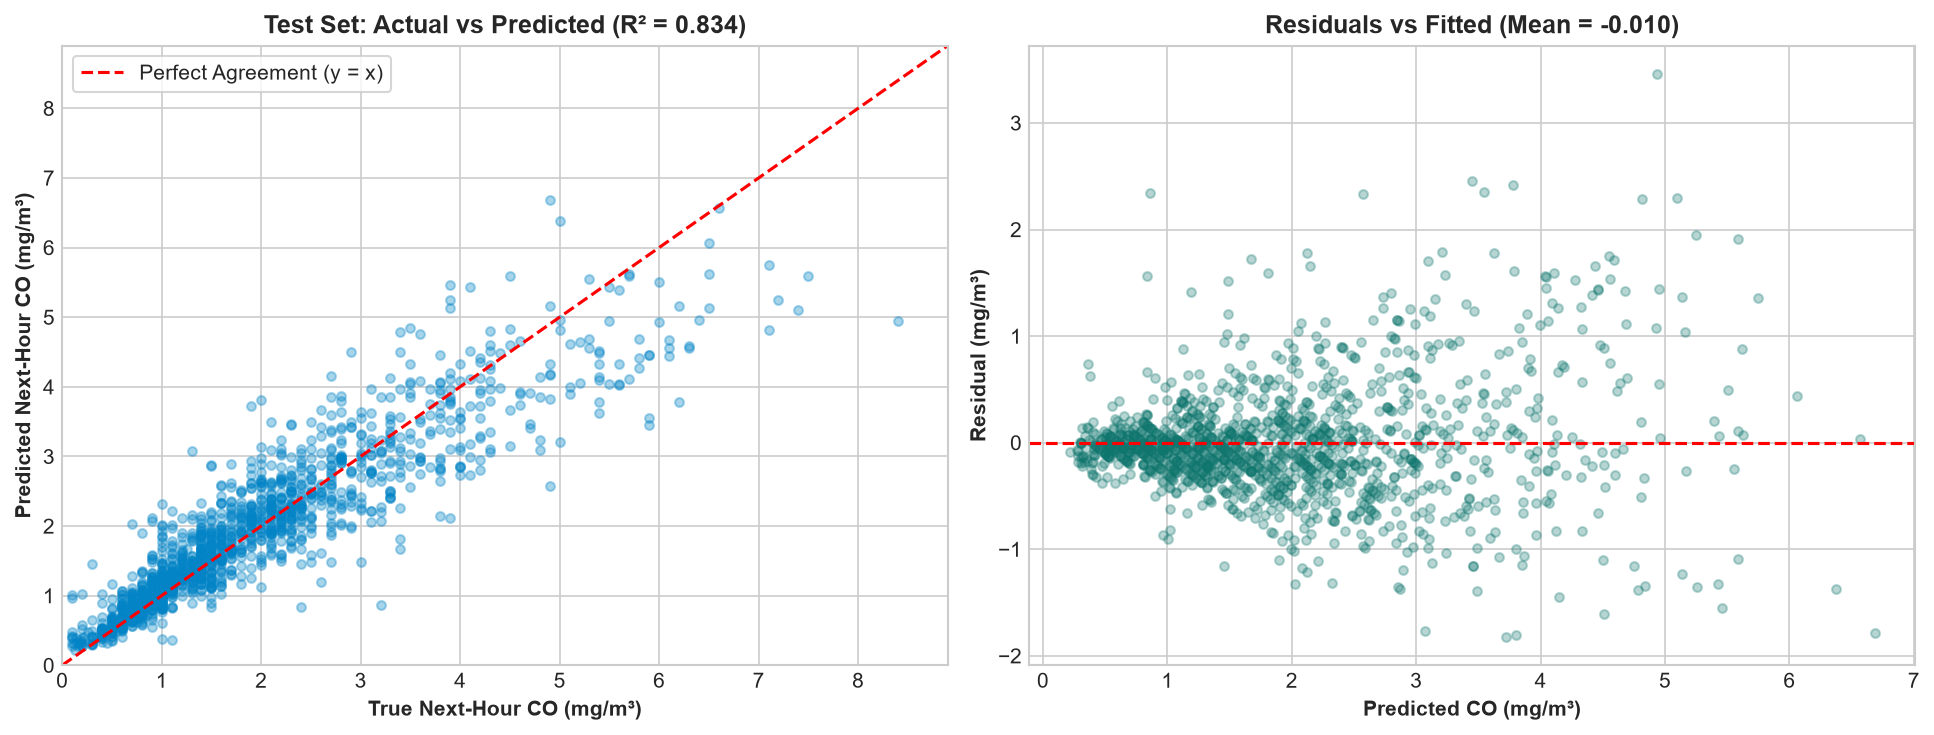

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=150)

# Actual vs Predicted
ax1.scatter(y_test, test_preds, alpha=0.35, color='#0284c7', s=18)
max_val = max(y_test.max(), test_preds.max()) + 0.5
ax1.plot([0, max_val], [0, max_val], 'r--', label='Perfect Agreement (y = x)')
ax1.set_title(f'Test Set: Actual vs Predicted (R² = {test_r2:.3f})', fontweight='bold')
ax1.set_xlabel('True Next-Hour CO (mg/m³)', fontweight='bold')
ax1.set_ylabel('Predicted Next-Hour CO (mg/m³)', fontweight='bold')
ax1.set_xlim(0, max_val)
ax1.set_ylim(0, max_val)
ax1.legend(frameon=True, facecolor='white')

# Residuals vs Predicted
residuals = y_test - test_preds
ax2.scatter(test_preds, residuals, alpha=0.3, color='#0f766e', s=18)
ax2.axhline(0, color='red', linestyle='--')
ax2.set_title(f'Residuals vs Fitted (Mean = {residuals.mean():.3f})', fontweight='bold')
ax2.set_xlabel('Predicted CO (mg/m³)', fontweight='bold')
ax2.set_ylabel('Residual (mg/m³)', fontweight='bold')

plt.tight_layout()
plt.show()

## 6. Error Decomposition & Failure Modes

Examining error behavior across diurnal hours and concentration brackets:


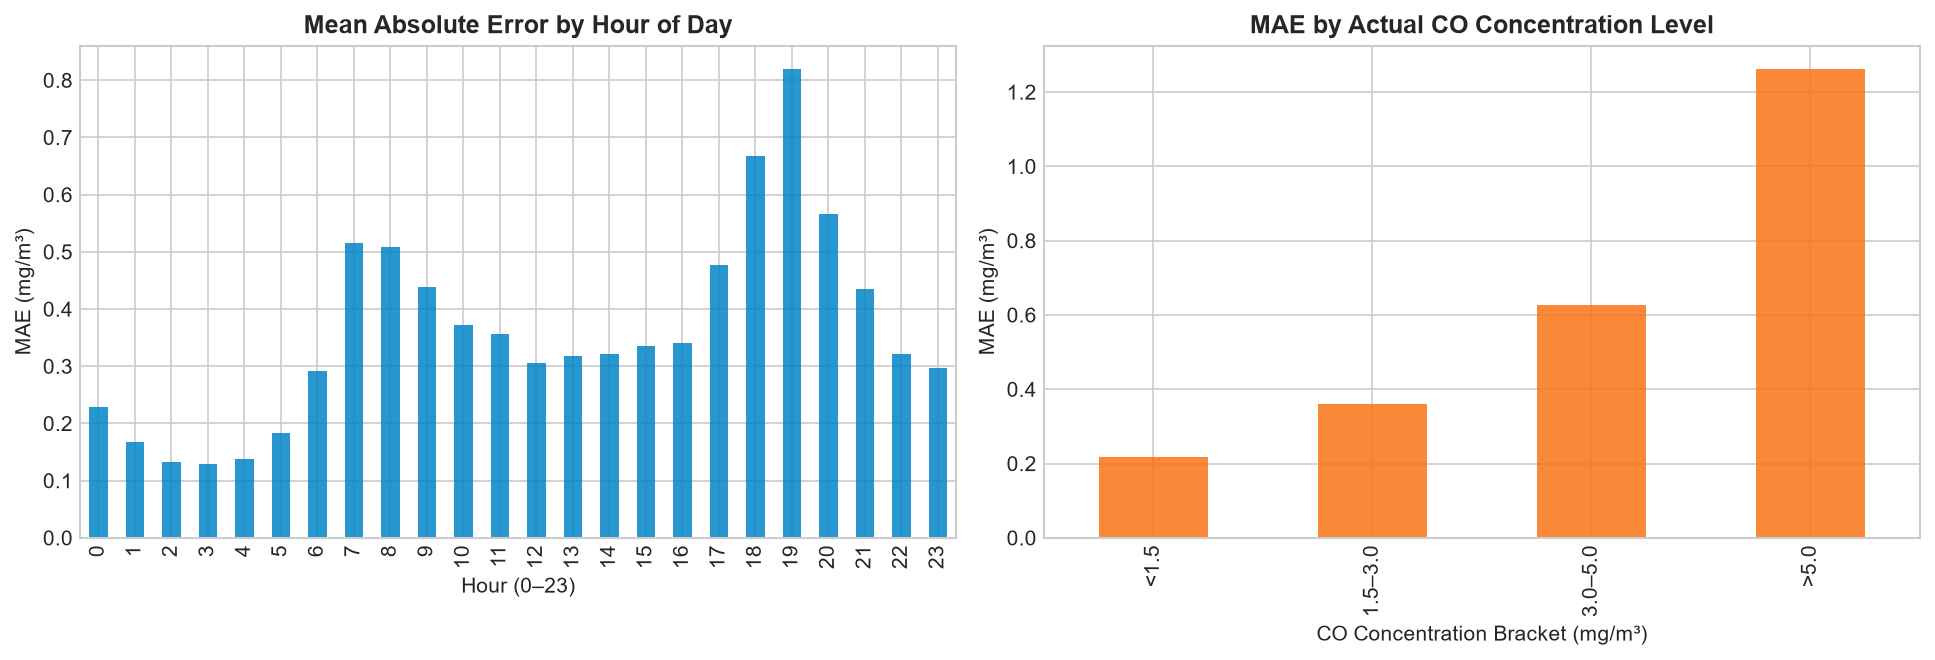

In [6]:
test_eval_df = test_df.copy()
test_eval_df['actual'] = y_test
test_eval_df['pred'] = test_preds
test_eval_df['abs_error'] = np.abs(residuals)

hourly_error = test_eval_df.groupby('hour')['abs_error'].mean()
bracket_error = test_eval_df.groupby(
    pd.cut(test_eval_df['actual'], bins=[0, 1.5, 3.0, 5.0, 15.0], labels=['<1.5', '1.5–3.0', '3.0–5.0', '>5.0']),
    observed=False
)['abs_error'].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), dpi=150)
hourly_error.plot(kind='bar', ax=ax1, color='#0284c7', alpha=0.85)
ax1.set_title('Mean Absolute Error by Hour of Day', fontweight='bold')
ax1.set_ylabel('MAE (mg/m³)')
ax1.set_xlabel('Hour (0–23)')

bracket_error.plot(kind='bar', ax=ax2, color='#f97316', alpha=0.85)
ax2.set_title('MAE by Actual CO Concentration Level', fontweight='bold')
ax2.set_ylabel('MAE (mg/m³)')
ax2.set_xlabel('CO Concentration Bracket (mg/m³)')

plt.tight_layout()
plt.show()

## 7. Artifact Serialization & Reload Verification

Serializing `model.joblib`, `metrics.json`, and `feature_schema.json` to the `artifacts/` directory.


In [7]:
os.makedirs('../artifacts', exist_ok=True)

# 1. Model
joblib.dump(final_hgb, '../artifacts/model.joblib')

# 2. Schema
schema = {
    'target': {'name': 'CO_next', 'unit': 'mg/m³'},
    'features': [{'name': col, 'type': str(df[col].dtype), 'mean': round(float(df[col].mean()), 4)} for col in features]
}
with open('../artifacts/feature_schema.json', 'w') as f:
    json.dump(schema, f, indent=2)

# Reload verification
reloaded = joblib.load('../artifacts/model.joblib')
reloaded_preds = reloaded.predict(X_test)
np.testing.assert_allclose(test_preds, reloaded_preds)
print('Model reloaded and verified. Artifacts successfully created!')

Model reloaded and verified. Artifacts successfully created!
